# JERICHON AFML_08 — Adaptive Directional Regime Strategy

## Объединённый эксперимент AFML_06 / AFML_07 / SC_05–SC_08

**Задача:** построить адаптивную стратегию, которая сначала определяет направленный рыночный режим, а затем передаёт событие отдельной модели торговли вверх или вниз. В нейтральном режиме сделок нет.

В этом ноутбуке:
- режимы определяются по причинным 474 признакам через `RobustScaler → PCA → GaussianMixture`;
- число компонент GMM выбирается по BIC только на обучающем участке; перед PCA удаляются inf/константные признаки, GMM использует несколько уровней регуляризации;
- направление каждого кластера определяется исключительно по уже завершившимся сделкам обучающего участка;
- отдельные модели `CatBoost` и `RandomForest` обучаются для LONG и SHORT;
- сигнал возникает на закрытии Dollar Bar, исполнение — на OPEN следующего бара;
- LONG/SHORT target и PnL рассчитываются от фактической цены входа на следующем OPEN, с барьерами и вертикальным выходом;
- тестирование — expanding walk-forward с purging незавершённых обучающих событий;
- не вводим отдельные классификационные метрики и пороги уверенности: сравниваем только торговые результаты.

**Важные ограничения:** GMM — не «истинные» рыночные режимы, а причинная группировка текущих признаков. Названия Bullish/Bearish/Neutral присваиваются кластерам только по прошлым завершённым результатам. В live после обучения модель режима получает только текущие признаки и не видит будущего. Результаты ноутбука — исследовательский walk-forward, не доказательство готовности к реальной торговле.

**Почему не используем напрямую AFML_07 target clusters:** там кластеризация будущих исходов нужна для исследования архетипов, но такой кластер нельзя присвоить текущему бару в live. Здесь кластеризуем только X (текущие доступные признаки), а будущие результаты используются только для исторической интерпретации кластеров на train.

## 1. Конфигурация

Начинаем с одного тикера. После проверки можно последовательно прогнать список. При 8 GB RAM оставляем умеренные размеры моделей и не используем `n_jobs=-1`.

In [21]:
from pathlib import Path
import os, sys, json, math, hashlib, warnings, gc, inspect, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestClassifier

# Установить catboost в активное окружение при необходимости:
# %pip install catboost
try:
    from catboost import CatBoostClassifier
except Exception as exc:
    raise ImportError("Для AFML_08 нужен CatBoost. Установи в окружение Jupyter: %pip install catboost") from exc

# Основные настройки
TICKER = "GAZP"             # затем можно добавить: GAZP, VTBR, YDEX, MTLR, SPBE
DOLLAR_THRESHOLD = 10_000_000   # согласовано с SC_05–SC_08; AFML_06 показал пользу ticker-specific tuning
CUSUM_THRESHOLD = 0.0015
PT_MULT = 0.8
SL_MULT = 0.8
VERTICAL_HORIZON = 30           # максимум баров в сделке
VOL_WINDOW = 75                 # окно оценки волатильности, только прошлые доходности
ROUND_TRIP_COST = 0.0006       # 0.12% полный круг; изменить под реальные тарифы/проскальзывание
RISK_FRACTION = 0.005           # риск на стоп: 0.5% текущего капитала
MAX_LEVERAGE = 3.0
MIN_CLUSTER_EVENTS = 40
MIN_DIRECTIONAL_EVENTS = 80
MIN_CLASS_COUNT = 15
GMM_COMPONENTS = range(2, 7)
PCA_VARIANCE = 0.90
PCA_MAX_COMPONENTS = 30
SEED = 20261102
N_JOBS = 2

RF_PARAMS = dict(n_estimators=250, max_depth=10, min_samples_leaf=8,
                 max_features="sqrt", class_weight="balanced_subsample",
                 random_state=SEED, n_jobs=N_JOBS)
CAT_PARAMS = dict(iterations=350, depth=6, learning_rate=0.04,
                  loss_function="Logloss", auto_class_weights="Balanced",
                  l2_leaf_reg=5.0, random_seed=SEED, verbose=False,
                  allow_writing_files=False, thread_count=N_JOBS)

CACHE_DIR_NAME = "data/for_ml/cache/afml08"
OUT_DIR_NAME = "research/afml/afml_08_adaptive_directional/results"
EXPECTED_FEATURES = 474
print("Ticker:", TICKER)
print("Dollar threshold:", f"{DOLLAR_THRESHOLD:,}")
print("Cost round-trip:", f"{ROUND_TRIP_COST*100:.3f}%")

Ticker: GAZP
Dollar threshold: 10,000,000
Cost round-trip: 0.060%


## 2. Подключение к каноническому AlgoPack pipeline

Используем тот же `jerichon_feature_pipeline.py`, что и AFML_06/07. Super Candles присоединяются только штатным causal helper `_attach_source`; `orderbook` не включаем в Super Candle признаки. Сохраняем `__available_at` / `__event_ts` только для аудита и не подаём их в модель.

In [22]:
def find_project_root(start=None):
    if PROJECT_ROOT is not None:
        p = Path(PROJECT_ROOT).expanduser().resolve()
        if not p.exists(): raise FileNotFoundError(f"PROJECT_ROOT не существует: {p}")
        return p
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    legacy = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON")
    if (legacy / "data" / "for_ml" / "storage" / "history").exists(): return legacy
    raise FileNotFoundError("Не найден корень JERICHON. Открой notebook из репозитория или задай PROJECT_ROOT вручную.")

PROJECT_ROOT = None  # при необходимости укажи абсолютный путь к корню репозитория
ROOT = find_project_root()
DATA_ROOT = ROOT / "data"
HISTORY_ROOT = DATA_ROOT / "for_ml" / "storage" / "history"
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.data.builders import jerichon_feature_pipeline as jfp
from src.data.labeling.cusum import cusum_filter

CACHE_DIR = ROOT / CACHE_DIR_NAME
OUT_DIR = ROOT / OUT_DIR_NAME
CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)
print("Feature pipeline:", inspect.getfile(jfp))


def available_dates(history_root, ticker):
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists(): dates.update(x.name for x in p.iterdir() if x.is_dir())
    return sorted(d for d in dates if len(d)==10 and d[4]=="-" and d[7]=="-")


def load_local_history(history_root, ticker):
    keys = ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")
    frames = {k: [] for k in keys}
    dates = available_dates(history_root, ticker)
    if not dates: raise FileNotFoundError(f"Нет локальной истории для {ticker}: {history_root}")
    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            p = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty: x = x.copy(); x["file_date"] = day; frames[key].append(x)
                except Exception as e: print("WARNING", p.name, repr(e))
        for key in ("tradestats", "obstats", "orderstats"):
            p = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty: x = x.copy(); x["file_date"] = day; frames[key].append(x)
                except Exception as e: print("WARNING", p.name, repr(e))
    out = {k: (pd.concat(v, ignore_index=True) if v else pd.DataFrame()) for k, v in frames.items()}
    missing = [s for s in ("trades", "tradestats", "obstats", "orderstats") if out[s].empty]
    if missing: raise RuntimeError(f"Не хватает локальных источников {missing}; API не вызывается.")
    print(f"Даты: {len(dates)} | {dates[0]} → {dates[-1]}")
    display(pd.DataFrame({"источник": list(out), "строк": [len(out[k]) for k in out]}))
    return out, dates


def normalize_time_col(frame, candidates=("bar_ts", "close_time", "ts")):
    frame = frame.copy()
    if "bar_ts" not in frame.columns:
        found = next((x for x in candidates if x in frame.columns), None)
        if found is None and isinstance(frame.index, pd.DatetimeIndex):
            frame = frame.reset_index().rename(columns={frame.index.name or "index": "bar_ts"})
        elif found is not None: frame = frame.rename(columns={found: "bar_ts"})
    if "bar_ts" not in frame.columns: raise RuntimeError(f"Нет временной колонки: {list(frame.columns)[:20]}")
    frame["bar_ts"] = pd.to_datetime(frame["bar_ts"], errors="coerce", utc=True)
    return frame.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)


def resolve_feature_frame(source, frames):
    if source in frames: return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches)==1: return frames[matches[0]]
    raise RuntimeError(f"Не сопоставлен feature frame {source}: {list(frames)}")


data, SAVED_DATES = load_local_history(HISTORY_ROOT, TICKER)

Project root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON
Feature pipeline: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Даты: 22 | 2026-09-24 → 2026-11-02


,источник,строк
0,candles,19619
1,trades,1970309
2,orderbook,440
3,tradestats,3942
4,obstats,3832
5,orderstats,3964


## 3. Построение Dollar Bars и 474 причинных признаков

Кэшируем результат. При изменении кода feature pipeline или его контракта увеличь `CACHE_VERSION`. Проверяем 73 базовых + 401 Super Candle = 474 числовых признака.

In [23]:
CACHE_VERSION = "afml08_causal_474_v1"

def cache_key(payload):
    raw = json.dumps(payload, sort_keys=True, default=str).encode("utf-8")
    return hashlib.sha256(raw).hexdigest()[:20]


def build_features_for_dollar_threshold(dollar_threshold):
    key = cache_key({"version": CACHE_VERSION, "ticker": TICKER, "threshold": int(dollar_threshold)})
    fp = CACHE_DIR / f"{TICKER}_{key}_features.parquet"
    bp = CACHE_DIR / f"{TICKER}_{key}_bars.parquet"
    if fp.exists() and bp.exists():
        try:
            ft, bars = normalize_time_col(pd.read_parquet(fp)), normalize_time_col(pd.read_parquet(bp))
            print(f"CACHE HIT: bars={len(bars):,}; features={len(ft):,}")
            return ft, bars
        except Exception as exc: print("Кэш не прочитан, пересобираю:", repr(exc))

    bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=int(dollar_threshold))
    if bars is None or bars.empty: raise RuntimeError("Dollar Bars пусты")
    bars = normalize_time_col(bars)
    base = jfp._base(bars.copy())
    if isinstance(base, tuple): base = base[0]
    if not isinstance(base, pd.DataFrame): raise TypeError("jfp._base должен вернуть DataFrame")
    base = normalize_time_col(base)

    bsc = bars.copy()
    if "ts" not in bsc.columns: bsc["ts"] = bsc["bar_ts"]
    if "CLOSE" not in bsc.columns:
        if "close" in bsc.columns: bsc["CLOSE"] = bsc["close"]
        else: raise RuntimeError("В Dollar Bars нет close/CLOSE")
    bsc["ts"] = pd.to_datetime(bsc["ts"], errors="coerce", utc=True)
    sc_result = jfp._build_sc_features(data, bsc.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True))
    feature_frames = sc_result[0] if isinstance(sc_result, tuple) else sc_result
    if not isinstance(feature_frames, dict): raise TypeError("_build_sc_features должен вернуть dict")

    causal = bars.copy()
    for source in ("tradestats", "obstats", "orderstats"):
        # Проверка availability вызывается для аудита, фактическое присоединение — штатным helper.
        jfp._choose_availability(data[source].copy(), source)
        attached = jfp._attach_source(causal, resolve_feature_frame(source, feature_frames), data[source], source)
        if isinstance(attached, pd.DataFrame): causal = attached

    base_cols = [x for x in base.columns if x != "bar_ts" and pd.api.types.is_numeric_dtype(base[x])]
    if len(base_cols) != 73: raise RuntimeError(f"Ожидалось 73 base features, найдено {len(base_cols)}")
    base_join = base[["bar_ts"] + base_cols].rename(columns={x: f"base__{x}" for x in base_cols})
    causal = normalize_time_col(causal).merge(base_join, on="bar_ts", how="left", validate="one_to_one")
    provenance = [x for x in causal.columns if x.endswith("__event_ts") or x.endswith("__available_at")]
    prefixes = ("tradestats__", "obstats__", "orderstats__")
    sc_cols = [x for x in causal.columns if x.startswith(prefixes) and x not in provenance and pd.api.types.is_numeric_dtype(causal[x])]
    feature_cols = [x for x in causal.columns if x.startswith("base__")] + sc_cols
    if len(feature_cols) != EXPECTED_FEATURES:
        raise RuntimeError(f"Найдено {len(feature_cols)} признаков вместо {EXPECTED_FEATURES}; остановка")
    ft = normalize_time_col(causal[["bar_ts"] + feature_cols + provenance])
    bars = normalize_time_col(bars)
    ft.to_parquet(fp, index=False); bars.to_parquet(bp, index=False)
    print(f"CACHE BUILD: bars={len(bars):,}; features={len(ft):,}")
    return ft, bars

features, bars = build_features_for_dollar_threshold(DOLLAR_THRESHOLD)
print("Features:", EXPECTED_FEATURES, "| bars:", len(bars))
display(bars.head(3))

CACHE HIT: bars=14,491; features=14,491
Features: 474 | bars: 14491


,open,high,low,close,volume,value,count,open_time,close_time,bar_ts
0,102.70,102.7,102.7,102.70,98230.0,10088221.0,108,2026-09-24 03:59:40+00:00,2026-09-24 03:59:40+00:00,2026-09-24 03:59:40+00:00
1,102.70,102.8,102.7,102.79,103150.0,10598897.9,285,2026-09-24 03:59:40+00:00,2026-09-24 04:00:02+00:00,2026-09-24 04:00:02+00:00
2,102.79,102.8,102.7,102.71,98480.0,10116145.1,87,2026-09-24 04:00:02+00:00,2026-09-24 04:00:21+00:00,2026-09-24 04:00:21+00:00


## 4. Построение направленных торговых исходов с исполнением на следующем OPEN

Событие возникает на закрытии бара. Вход — строго на OPEN следующего бара. Барьеры LONG и SHORT симметричны относительно цены входа. Если TP и SL попали в один бар, консервативно считаем, что первым сработал SL. Если ни один барьер не достигнут, закрываем позицию по CLOSE последнего бара горизонта.

Важное отличие от AFML_07: здесь метки и доходность считаются от фактической цены следующего OPEN, а не от CLOSE сигнального бара. Это устраняет разрыв между сигналом и моделируемым исполнением.

In [24]:
def get_ohlc_frame(bars_frame):
    b = normalize_time_col(bars_frame).copy().set_index("bar_ts").sort_index()
    aliases = {"open": ["open", "OPEN"], "high": ["high", "HIGH"],
               "low": ["low", "LOW"], "close": ["close", "CLOSE"]}
    out = pd.DataFrame(index=b.index)
    for dst, opts in aliases.items():
        col = next((x for x in opts if x in b.columns), None)
        if col is None: raise RuntimeError(f"Не найдена OHLC колонка {dst}; columns={list(b.columns)}")
        out[dst] = pd.to_numeric(b[col], errors="coerce")
    out = out.replace([np.inf, -np.inf], np.nan).dropna()
    return out


def build_directional_outcomes(bars_frame, cusum_threshold, pt_mult, sl_mult, horizon, vol_window, round_trip_cost):
    ohlc = get_ohlc_frame(bars_frame)
    close = ohlc["close"].astype(float)
    logret = np.log(close).diff()
    # Текущая оценка волатильности использует только доходности, уже известные к закрытию события.
    vol = logret.ewm(span=int(vol_window), min_periods=max(20, int(vol_window)//3), adjust=False).std()
    event_times = pd.DatetimeIndex(cusum_filter(close, threshold=float(cusum_threshold)))
    event_times = event_times[event_times.isin(ohlc.index)].drop_duplicates().sort_values()
    pos = pd.Series(np.arange(len(ohlc)), index=ohlc.index)
    op = ohlc["open"].to_numpy(float); hi = ohlc["high"].to_numpy(float)
    lo = ohlc["low"].to_numpy(float); cl = ohlc["close"].to_numpy(float)
    vv = vol.reindex(ohlc.index).to_numpy(float)
    rows = []
    for ts in event_times:
        i = int(pos.loc[ts]); entry_i = i + 1
        if entry_i >= len(ohlc) or not np.isfinite(vv[i]) or vv[i] <= 0: continue
        entry = op[entry_i]
        if not np.isfinite(entry) or entry <= 0: continue
        tp_pct = float(pt_mult) * float(vv[i]); sl_pct = float(sl_mult) * float(vv[i])
        if not (0 < tp_pct < 0.25 and 0 < sl_pct < 0.25): continue
        end_i = min(entry_i + int(horizon) - 1, len(ohlc) - 1)
        if end_i < entry_i: continue
        long_exit = short_exit = None
        long_reason = short_reason = "vertical"
        long_t1 = short_t1 = ohlc.index[end_i]
        for j in range(entry_i, end_i + 1):
            # LONG: stop-first при одновременном касании TP и SL в одной свече.
            l_sl, l_tp = entry * (1-sl_pct), entry * (1+tp_pct)
            if lo[j] <= l_sl:
                long_exit, long_reason, long_t1 = l_sl, "SL", ohlc.index[j]; break
            if hi[j] >= l_tp:
                long_exit, long_reason, long_t1 = l_tp, "TP", ohlc.index[j]; break
        for j in range(entry_i, end_i + 1):
            s_sl, s_tp = entry * (1+sl_pct), entry * (1-tp_pct)
            if hi[j] >= s_sl:
                short_exit, short_reason, short_t1 = s_sl, "SL", ohlc.index[j]; break
            if lo[j] <= s_tp:
                short_exit, short_reason, short_t1 = s_tp, "TP", ohlc.index[j]; break
        if long_exit is None: long_exit = cl[end_i]
        if short_exit is None: short_exit = cl[end_i]
        long_gross = long_exit / entry - 1.0
        short_gross = entry / short_exit - 1.0
        long_net = long_gross - float(round_trip_cost)
        short_net = short_gross - float(round_trip_cost)
        rows.append({
            "event_ts": ts, "entry_ts": ohlc.index[entry_i], "entry_i": entry_i,
            "entry_price": entry, "volatility": float(vv[i]), "tp_pct": tp_pct, "sl_pct": sl_pct,
            "long_net_return": long_net, "short_net_return": short_net,
            "long_success": int(long_net > 0), "short_success": int(short_net > 0),
            "long_exit_ts": long_t1, "short_exit_ts": short_t1,
            "long_exit_i": int(pos.loc[long_t1]), "short_exit_i": int(pos.loc[short_t1]),
            "long_exit_reason": long_reason, "short_exit_reason": short_reason,
            "t1": max(long_t1, short_t1),
        })
    out = pd.DataFrame(rows)
    if out.empty: raise RuntimeError("Не удалось построить направленные исходы; проверь OHLC/CUSUM/параметры")
    return out.set_index("event_ts").sort_index(), ohlc

outcomes, ohlc = build_directional_outcomes(
    bars, CUSUM_THRESHOLD, PT_MULT, SL_MULT, VERTICAL_HORIZON,
    VOL_WINDOW, ROUND_TRIP_COST
)
print("Events with executable next-OPEN:", len(outcomes))
display(outcomes.head())
print("Средний net return LONG / SHORT:", outcomes[["long_net_return", "short_net_return"]].mean().to_dict())

Events with executable next-OPEN: 2646


,entry_ts,entry_i,entry_price,volatility,tp_pct,sl_pct,long_net_return,short_net_return,long_success,short_success,long_exit_ts,short_exit_ts,long_exit_i,short_exit_i,long_exit_reason,short_exit_reason,t1
event_ts,,,,,,,,,,,,,,,,,
2026-09-24 04:08:46+00:00,2026-09-24 04:09:30+00:00,28,102.46,0.001017,0.000814,0.000814,-0.001414,0.000214,0,1,2026-09-24 04:10:39+00:00,2026-09-24 04:10:39+00:00,30,30,SL,TP,2026-09-24 04:10:39+00:00
2026-09-24 04:10:39+00:00,2026-09-24 04:11:50+00:00,31,102.33,0.001004,0.000803,0.000803,-0.001403,0.000204,0,1,2026-09-24 04:11:50+00:00,2026-09-24 04:11:50+00:00,31,31,SL,TP,2026-09-24 04:11:50+00:00
2026-09-24 04:12:39+00:00,2026-09-24 04:13:04+00:00,34,102.10,0.001002,0.000802,0.000802,-0.001402,0.000202,0,1,2026-09-24 04:13:04+00:00,2026-09-24 04:13:04+00:00,34,34,SL,TP,2026-09-24 04:13:04+00:00
2026-09-24 04:13:12+00:00,2026-09-24 04:13:22+00:00,36,101.91,0.001014,0.000811,0.000811,0.000211,-0.001410,1,0,2026-09-24 04:14:24+00:00,2026-09-24 04:14:24+00:00,37,37,TP,SL,2026-09-24 04:14:24+00:00
2026-09-24 04:14:24+00:00,2026-09-24 04:14:50+00:00,38,102.00,0.001021,0.000816,0.000816,0.000216,-0.001416,1,0,2026-09-24 04:15:31+00:00,2026-09-24 04:15:31+00:00,39,39,TP,SL,2026-09-24 04:15:31+00:00


Средний net return LONG / SHORT: {'long_net_return': -0.0006151289586289164, 'short_net_return': -0.0006324746518293392}


## 5. Формирование X и аудит причинности

Берём только 474 числовых признака, не используем `available_at` / `event_ts` как признаки. Признаки на момент события должны быть уже доступны по контракту `jfp._attach_source`. Дополнительно проверяем временное выравнивание и пропуски.

In [25]:
ft = features.copy().set_index("bar_ts").sort_index()
provenance_cols = [x for x in ft.columns if x.endswith("__event_ts") or x.endswith("__available_at")]
feature_cols = [x for x in ft.columns if x not in provenance_cols and pd.api.types.is_numeric_dtype(ft[x])]
if len(feature_cols) != EXPECTED_FEATURES:
    raise RuntimeError(f"В X найдено {len(feature_cols)} признаков, ожидалось {EXPECTED_FEATURES}")
X_all = ft[feature_cols].copy()
X_all = X_all.replace([np.inf, -np.inf], np.nan)
X_all.index = pd.to_datetime(X_all.index, utc=True)
X_all = X_all[~X_all.index.duplicated(keep="last")].sort_index()
common = outcomes.index.intersection(X_all.index)
outcomes = outcomes.loc[common].copy()
X_all = X_all.loc[common].copy()
if len(X_all) < 300: raise RuntimeError(f"Слишком мало совпавших событий: {len(X_all)}")

# Диагностика источников: сколько признаков и насколько они заполнены.
source_report = pd.DataFrame({
    "family": ["base" if x.startswith("base__") else x.split("__",1)[0] for x in feature_cols],
    "missing_share": X_all.isna().mean().to_numpy()
}).groupby("family").agg(features=("missing_share","size"), median_missing=("missing_share","median"), max_missing=("missing_share","max"))
display(source_report)
print("Aligned events:", len(X_all), "| date range:", X_all.index.min(), "→", X_all.index.max())

,features,median_missing,max_missing
family,,,
base,73,0.000000,0.000000
obstats,136,0.001890,0.013228
orderstats,171,0.000000,0.004535
tradestats,94,0.000378,0.093726


Aligned events: 2646 | date range: 2026-09-24 04:08:46+00:00 → 2026-11-02 16:02:12+00:00


## 6. Walk-forward folds и purging

Используем три последовательных тестовых отрезка. На каждом шаге модель обучается только на прошлом. Из train удаляются события, исход которых не завершился до начала тестового периода. Тестовые события, исход которых не успел завершиться до конца доступной истории, исключаются из итогового расчёта.

In [26]:
def make_walk_forward_folds(index, fractions=(0.50, 0.65, 0.80)):
    n = len(index)
    cuts = [int(n*f) for f in fractions] + [n]
    folds = []
    for k in range(len(cuts)-1):
        a, b = cuts[k], cuts[k+1]
        if a < 100 or b-a < 30: continue
        folds.append({"name": f"WF{k+1}", "train_candidate": index[:a],
                      "test_candidate": index[a:b], "test_start": index[a], "test_end": index[b-1]})
    return folds


def purge_train(train_idx, outcome_frame, test_start):
    t1 = pd.to_datetime(outcome_frame.reindex(train_idx)["t1"], utc=True, errors="coerce")
    return pd.DatetimeIndex(train_idx[(t1 < pd.Timestamp(test_start)).fillna(False).to_numpy()])

folds = make_walk_forward_folds(X_all.index)
print("Folds:", [(f["name"], len(f["train_candidate"]), len(f["test_candidate"])) for f in folds])
if len(folds) < 2: raise RuntimeError("Недостаточно данных для двух walk-forward folds")

Folds: [('WF1', 1323, 396), ('WF2', 1719, 397), ('WF3', 2116, 530)]


## 7. Каузальное определение режимов: RobustScaler → PCA → GMM

GMM обучается только на train-признаках. Число компонент выбирается по BIC на том же train. На тесте вызывается только `predict()`.

После кластеризации каждому train-кластеру присваивается направление по среднему различию между net LONG и net SHORT результатом **только на завершившихся train-событиях**:
- положительное преимущество LONG → `BULLISH`;
- отрицательное преимущество LONG → `BEARISH`;
- недостаточная поддержка или слабое преимущество → `NEUTRAL`.

Это не использует будущие данные теста и пригодно для live: сохранённые scaler/PCA/GMM + таблица направлений кластера можно применить к следующему событию.

In [27]:
def fit_regime_model(X_train, y_train_outcomes):
    """
    Обучение режима только на train X.
    Все статистики импутации, масштабирования и PCA оцениваются только на train.
    Нефинитные и константные признаки удаляются до PCA.
    """
    x_raw = X_train.copy()
    x_raw = x_raw.apply(pd.to_numeric, errors="coerce")
    x_raw = x_raw.replace([np.inf, -np.inf], np.nan)

    # Оставляем только признаки с достаточным количеством конечных наблюдений.
    finite_counts = x_raw.notna().sum()
    keep_cols = finite_counts[finite_counts >= max(10, int(0.05 * len(x_raw)))].index.tolist()
    if len(keep_cols) < 2:
        raise RuntimeError(
            f"Для GMM осталось менее 2 пригодных признаков: {len(keep_cols)}. "
            f"Исходных колонок={X_train.shape[1]}, train rows={len(X_train)}"
        )

    x_raw = x_raw[keep_cols]
    medians = x_raw.median(axis=0).replace([np.inf, -np.inf], np.nan)
    valid_medians = medians[medians.notna()].index.tolist()
    x_raw = x_raw[valid_medians]
    medians = medians[valid_medians]
    if x_raw.shape[1] < 2:
        raise RuntimeError("После удаления полностью пустых признаков осталось менее 2 колонок")

    x_imp = x_raw.fillna(medians).astype(np.float64)
    # Удаляем константы и почти константы по train.
    nunique = x_imp.nunique(dropna=False)
    variable_cols = nunique[nunique > 1].index.tolist()
    x_imp = x_imp[variable_cols]
    medians = medians[variable_cols]
    if x_imp.shape[1] < 2:
        raise RuntimeError("После удаления константных признаков осталось менее 2 колонок")

    x_values = x_imp.to_numpy(dtype=np.float64, copy=True)
    if not np.isfinite(x_values).all():
        bad = int((~np.isfinite(x_values)).sum())
        raise RuntimeError(f"Нефинитные значения остались после импутации: {bad}")

    scaler = RobustScaler(quantile_range=(10, 90))
    x_scaled = scaler.fit_transform(x_values)
    if not np.isfinite(x_scaled).all():
        raise RuntimeError("RobustScaler сформировал NaN/inf; проверь масштаб и выбросы признаков")

    # Константы уже удалены до scaler. Признаки с нулевым IQR могут остаться
    # неизменёнными после RobustScaler; PCA корректно обработает их как нулевую дисперсию.
    scaled_cols = list(variable_cols)

    n_components = min(PCA_MAX_COMPONENTS, x_scaled.shape[1], x_scaled.shape[0] - 1)
    if n_components < 2:
        raise RuntimeError(f"Недостаточно размерности для PCA: n_components={n_components}")

    # Сначала пробуем сохранить заданную долю дисперсии, затем жёстко ограничиваем размерность.
    pca = PCA(n_components=min(PCA_VARIANCE, 0.999), svd_solver="full")
    z = pca.fit_transform(x_scaled)
    if z.shape[1] > PCA_MAX_COMPONENTS:
        pca = PCA(n_components=n_components, svd_solver="randomized", random_state=SEED)
        z = pca.fit_transform(x_scaled)
    if z.shape[1] < 1 or not np.isfinite(z).all():
        raise RuntimeError(
            f"PCA сформировал некорректную матрицу: shape={z.shape}, "
            f"finite={bool(np.isfinite(z).all())}"
        )

    # GMM может быть нестабилен на почти вырожденных компонентах.
    # Пробуем несколько уровней регуляризации; BIC сравнивается на одной train-матрице.
    candidates, failures = [], []
    for k in GMM_COMPONENTS:
        if len(z) <= int(k) * 5 or z.shape[1] < 1:
            failures.append(f"k={k}: недостаточно наблюдений для {z.shape[1]} компонент")
            continue
        for reg in (1e-4, 1e-3, 1e-2):
            try:
                gm = GaussianMixture(
                    n_components=int(k),
                    covariance_type="diag",
                    reg_covar=reg,
                    n_init=3,
                    max_iter=300,
                    init_params="kmeans",
                    random_state=SEED
                )
                gm.fit(z)
                if not np.isfinite(gm.lower_bound_):
                    raise ValueError("GMM lower_bound_ не конечен")
                bic = float(gm.bic(z))
                if np.isfinite(bic):
                    candidates.append((bic, gm, reg))
            except Exception as exc:
                failures.append(f"k={k}, reg={reg:g}: {type(exc).__name__}: {exc}")

    if not candidates:
        diagnostic = "\n".join(failures[-15:])
        raise RuntimeError(
            "Не удалось обучить ни одну конфигурацию GMM.\n"
            f"Диагностика: train={x_scaled.shape}, PCA={z.shape}, "
            f"finite_X={np.isfinite(x_scaled).all()}, finite_PCA={np.isfinite(z).all()}\n"
            f"Ошибки конфигураций:\n{diagnostic}"
        )

    _, gmm, selected_reg = min(candidates, key=lambda item: item[0])
    train_clusters = pd.Series(gmm.predict(z), index=X_train.index, name="cluster")

    # Сопоставляем кластеры с направлением только по завершённым исходам train.
    aligned = y_train_outcomes.reindex(X_train.index)
    direction_map = {}
    for cluster_id, idx in train_clusters.groupby(train_clusters).groups.items():
        part = aligned.loc[idx]
        edge = (
            pd.to_numeric(part["long_net_return"], errors="coerce")
            - pd.to_numeric(part["short_net_return"], errors="coerce")
        ).replace([np.inf, -np.inf], np.nan).dropna()

        if len(edge) < MIN_CLUSTER_EVENTS:
            direction = "NEUTRAL"
        else:
            mean_edge = float(edge.mean())
            if mean_edge > 0.0002:
                direction = "BULLISH"
            elif mean_edge < -0.0002:
                direction = "BEARISH"
            else:
                direction = "NEUTRAL"

        direction_map[int(cluster_id)] = {
            "direction": direction,
            "n_train": int(len(idx)),
            "mean_long_net": float(pd.to_numeric(part["long_net_return"], errors="coerce").mean()),
            "mean_short_net": float(pd.to_numeric(part["short_net_return"], errors="coerce").mean()),
            "direction_edge": float(edge.mean()) if len(edge) else np.nan,
        }

    state = {
        "columns": scaled_cols,
        "medians": medians,
        "scaler": scaler,
        "scaled_columns": scaled_cols,
        "pca": pca,
        "gmm": gmm,
        "gmm_reg_covar": selected_reg,
        "direction_map": direction_map,
    }
    return state, train_clusters

def predict_regime(state, X_frame):
    x = X_frame.reindex(columns=state["columns"]).copy()
    x = x.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    x = x.fillna(state["medians"]).astype(np.float64)
    x_values = x.to_numpy(copy=True)
    if not np.isfinite(x_values).all():
        raise RuntimeError("В predict_regime после train-медианной импутации остались NaN/inf")
    z = state["pca"].transform(state["scaler"].transform(x_values))
    if not np.isfinite(z).all():
        raise RuntimeError("В predict_regime PCA сформировал NaN/inf")
    cluster = state["gmm"].predict(z)
    direction = [
        state["direction_map"].get(int(k), {}).get("direction", "NEUTRAL")
        for k in cluster
    ]
    return pd.DataFrame({"cluster": cluster, "regime": direction}, index=X_frame.index)

# Быстрая визуальная памятка по выбранной логике.
print("Regime model: GMM fitted on train X only; cluster direction mapped from train-only realized returns.")

Regime model: GMM fitted on train X only; cluster direction mapped from train-only realized returns.


## 8. Направленные модели: только CatBoost и RandomForest

Две независимые задачи:
- LONG-модель обучается только на событиях train, чьи GMM-кластеры признаны `BULLISH`. Цель — положительный net-результат LONG.
- SHORT-модель обучается только на событиях train, чьи GMM-кластеры признаны `BEARISH`. Цель — положительный net-результат SHORT.

На тесте сначала применяется GMM-режим, затем вызывается только соответствующая направленная модель. Противоположные сигналы не рассматриваются. Никаких дополнительных confidence-порогов нет: решение принимает `predict()` модели.

In [28]:
def make_model(model_name):
    if model_name == "RandomForest": return RandomForestClassifier(**RF_PARAMS)
    if model_name == "CatBoost": return CatBoostClassifier(**CAT_PARAMS)
    raise ValueError(model_name)


def prepare_model_data(X_train, X_test):
    # Импутация по train; не допускаем утечки медиан из теста.
    med = X_train.median().fillna(0.0)
    a = X_train.fillna(med).replace([np.inf,-np.inf],np.nan).fillna(med)
    b = X_test.reindex(columns=X_train.columns).fillna(med).replace([np.inf,-np.inf],np.nan).fillna(med)
    return a.astype(np.float32), b.astype(np.float32)


def fit_directional_model(model_name, side, X_train, train_regimes, train_outcomes):
    wanted = "BULLISH" if side == "LONG" else "BEARISH"
    idx = train_regimes.index[train_regimes["regime"] == wanted]
    idx = idx.intersection(X_train.index).intersection(train_outcomes.index)
    y_col = "long_success" if side == "LONG" else "short_success"
    if len(idx) < MIN_DIRECTIONAL_EVENTS: return None, {"status":"TOO_FEW_DIRECTIONAL_EVENTS", "n":len(idx)}
    y = train_outcomes.loc[idx, y_col].astype(int)
    counts = y.value_counts()
    if len(counts) < 2 or int(counts.min()) < MIN_CLASS_COUNT:
        return None, {"status":"INSUFFICIENT_BOTH_CLASSES", "n":len(idx), "class_counts":counts.to_dict()}
    model = make_model(model_name)
    x_fit = X_train.loc[idx]
    # CatBoost/RF получают исходные признаки; GMM preprocessing не подменяет feature representation.
    med = x_fit.median().fillna(0.0)
    x_fit = x_fit.replace([np.inf,-np.inf],np.nan).fillna(med).astype(np.float32)
    model.fit(x_fit, y)
    return model, {"status":"OK", "n":len(idx), "class_counts":counts.to_dict()}


def size_trade_return(net_return, stop_pct, risk_fraction=RISK_FRACTION, max_leverage=MAX_LEVERAGE):
    if not np.isfinite(net_return) or not np.isfinite(stop_pct) or stop_pct <= 0: return 0.0
    notional_fraction = min(float(risk_fraction) / float(stop_pct), float(max_leverage))
    return notional_fraction * float(net_return)


def execute_non_overlapping(signals, outcome_frame, side):
    if signals.empty: return pd.DataFrame()
    ret_col = "long_net_return" if side == "LONG" else "short_net_return"
    exit_col = "long_exit_i" if side == "LONG" else "short_exit_i"
    rows = []
    last_exit_i = -1
    for ts, row in signals.sort_index().iterrows():
        o = outcome_frame.loc[ts]
        entry_i = int(o["entry_i"])
        if entry_i <= last_exit_i: continue
        net = float(o[ret_col])
        cap_ret = size_trade_return(net, float(o["sl_pct"]))
        rows.append({"event_ts":ts, "entry_ts":o["entry_ts"], "side":side,
                     "entry_price":float(o["entry_price"]), "net_return_pct":net*100,
                     "capital_return_pct":cap_ret*100, "profitable":int(net>0),
                     "exit_reason":o["long_exit_reason" if side=="LONG" else "short_exit_reason"],
                     "exit_i":int(o[exit_col]), "t1":o["long_exit_ts" if side=="LONG" else "short_exit_ts"]})
        last_exit_i = int(o[exit_col])
    return pd.DataFrame(rows)


def summarize_trades(trades, initial_capital=1_000_000.0):
    if trades is None or trades.empty:
        return {"trades":0,"profitable_trades":0,"win_rate_pct":np.nan,"net_profit_rub":0.0,
                "total_return_pct":0.0,"profit_factor":np.nan,"max_drawdown_pct":0.0}
    r = trades["capital_return_pct"].to_numpy(float) / 100.0
    equity = initial_capital * np.cumprod(1.0 + r)
    peak = np.maximum.accumulate(np.r_[initial_capital, equity])[1:]
    dd = equity / peak - 1.0
    gains = trades.loc[trades["capital_return_pct"]>0,"capital_return_pct"].sum()
    losses = -trades.loc[trades["capital_return_pct"]<0,"capital_return_pct"].sum()
    return {"trades":int(len(trades)), "profitable_trades":int((trades["profitable"]==1).sum()),
            "win_rate_pct":float(trades["profitable"].mean()*100),
            "net_profit_rub":float(equity[-1]-initial_capital),
            "total_return_pct":float((equity[-1]/initial_capital-1)*100),
            "profit_factor":float(gains/losses) if losses>0 else np.inf,
            "max_drawdown_pct":float(dd.min()*100) if len(dd) else 0.0}

print("Directional model classes ready: CatBoost + RandomForest only.")

Directional model classes ready: CatBoost + RandomForest only.


## 9. Запуск адаптивной walk-forward стратегии

Для каждого тестового периода:
1. удаляем из train события, чьи исходы не завершились до начала теста;
2. обучаем GMM только на train X и назначаем train-кластерам направление по train-исходам;
3. обучаем LONG/SHORT модели только на соответствующих направленных режимах;
4. присваиваем тестовым событиям режим через `GMM.predict()`;
5. открываем LONG только в `BULLISH`, SHORT только в `BEARISH`, Neutral пропускаем;
6. сигнал исполняется на следующем OPEN, одновременно может быть открыта только одна позиция на тикер.

CatBoost и RandomForest тестируются как две альтернативные реализации каждой направленной модели. Они не смешиваются в ансамбль.

In [29]:
all_fold_rows, all_trade_rows, all_regime_rows = [], [], []

for fold in folds:
    print(f"\\n========== {fold['name']} ==========")
    test_idx = pd.DatetimeIndex(fold["test_candidate"])
    test_idx = test_idx[outcomes.reindex(test_idx)["t1"].notna().to_numpy()]
    fold_test_end = ohlc.index.max() if fold["name"] == folds[-1]["name"] else pd.Timestamp(fold["test_end"])
    test_idx = test_idx[(pd.to_datetime(outcomes.reindex(test_idx)["t1"], utc=True) <= fold_test_end).to_numpy()]
    train_idx = purge_train(pd.DatetimeIndex(fold["train_candidate"]), outcomes, fold["test_start"])
    if len(train_idx) < 200 or len(test_idx) < 30:
        print("Пропуск: мало train/test после purging", len(train_idx), len(test_idx)); continue
    Xtr, Xte = X_all.loc[train_idx], X_all.loc[test_idx]
    otr, ote = outcomes.loc[train_idx], outcomes.loc[test_idx]
    print("Train:",len(train_idx),"Test:",len(test_idx),"| purge:",len(fold["train_candidate"])-len(train_idx))

    regime_state, train_clusters = fit_regime_model(Xtr, otr)
    train_regimes = predict_regime(regime_state, Xtr)
    test_regimes = predict_regime(regime_state, Xte)
    map_rows = []
    for cid, info in regime_state["direction_map"].items():
        map_rows.append({"fold":fold["name"],"cluster":cid,**info})
    all_regime_rows.extend(map_rows)
    print("Train regime map:")
    display(pd.DataFrame(map_rows).sort_values("cluster"))
    print("Test regime distribution:")
    display(test_regimes["regime"].value_counts(normalize=True).rename("share").to_frame())

    for model_name in ("CatBoost", "RandomForest"):
        directional_signals = []
        model_status = {}
        for side in ("LONG", "SHORT"):
            model, status = fit_directional_model(model_name, side, Xtr, train_regimes, otr)
            model_status[side] = status
            if model is None: continue
            regime_wanted = "BULLISH" if side == "LONG" else "BEARISH"
            eligible = test_regimes.index[test_regimes["regime"] == regime_wanted]
            if len(eligible)==0: continue
            xfit = Xtr.loc[train_regimes.index[train_regimes["regime"] == regime_wanted]]
            # Та же train-only медианная импутация, что и при обучении конкретной стороны.
            fit_idx = xfit.index.intersection(otr.index)
            med = Xtr.loc[fit_idx].median().fillna(0.0)
            x_test = Xte.loc[eligible].replace([np.inf,-np.inf],np.nan).fillna(med).astype(np.float32)
            pred = pd.Series(np.asarray(model.predict(x_test)).reshape(-1).astype(int), index=eligible)
            selected = pred[pred == 1].index
            if len(selected):
                s = pd.DataFrame({"side":side}, index=selected)
                directional_signals.append(s)
        if directional_signals:
            signal_frame = pd.concat(directional_signals).sort_index()
            # При конфликте одного event timestamp (теоретически) — не торгуем.
            signal_frame = signal_frame[~signal_frame.index.duplicated(keep=False)]
        else:
            signal_frame = pd.DataFrame(columns=["side"])

        # Исполнение единой позиции: события LONG/SHORT сортируются по времени.
        trade_rows = []
        last_exit_i = -1
        for ts, sig in signal_frame.sort_index().iterrows():
            side = sig["side"]
            o = ote.loc[ts]
            if int(o["entry_i"]) <= last_exit_i: continue
            ret_col = "long_net_return" if side=="LONG" else "short_net_return"
            exit_col = "long_exit_i" if side=="LONG" else "short_exit_i"
            reason_col = "long_exit_reason" if side=="LONG" else "short_exit_reason"
            time_col = "long_exit_ts" if side=="LONG" else "short_exit_ts"
            net = float(o[ret_col]); cap_ret = size_trade_return(net, float(o["sl_pct"]))
            trade_rows.append({"ticker":TICKER,"fold":fold["name"],"model":model_name,"side":side,
                "event_ts":ts,"entry_ts":o["entry_ts"],"entry_price":float(o["entry_price"]),
                "net_return_pct":net*100,"capital_return_pct":cap_ret*100,"profitable":int(net>0),
                "exit_reason":o[reason_col],"exit_ts":o[time_col],"exit_i":int(o[exit_col])})
            last_exit_i = int(o[exit_col])
        trades = pd.DataFrame(trade_rows)
        if not trades.empty: all_trade_rows.extend(trade_rows)
        summary = summarize_trades(trades)
        all_fold_rows.append({"ticker":TICKER,"fold":fold["name"],"model":model_name,
            **summary,"long_train_status":model_status["LONG"]["status"],
            "long_train_events":model_status["LONG"].get("n",0),
            "short_train_status":model_status["SHORT"]["status"],
            "short_train_events":model_status["SHORT"].get("n",0),
            "test_events":len(test_idx),"test_signals_before_overlap":len(signal_frame)})
        print(model_name, summary, model_status)
        del trades
    del regime_state, train_clusters, train_regimes, test_regimes
    gc.collect()

fold_results = pd.DataFrame(all_fold_rows)
trade_results = pd.DataFrame(all_trade_rows)
regime_map_results = pd.DataFrame(all_regime_rows)
display(fold_results)
print("Trades:", len(trade_results))

\n========== WF1 ==========
Train: 1323 Test: 395 | purge: 0


C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than avai

Train regime map:


,fold,cluster,direction,n_train,mean_long_net,mean_short_net,direction_edge
0,WF1,0,NEUTRAL,1197,-0.000634,-0.000623,-0.000010
1,WF1,1,NEUTRAL,3,0.000104,-0.001304,0.001408
2,WF1,2,NEUTRAL,2,-0.001231,0.000031,-0.001262
3,WF1,3,NEUTRAL,2,-0.000479,-0.000721,0.000242
4,WF1,4,NEUTRAL,23,0.000342,-0.001605,0.001947
5,WF1,5,BEARISH,96,-0.000763,-0.000525,-0.000238


Test regime distribution:


,share
regime,
NEUTRAL,0.974684
BEARISH,0.025316


... (11 outputs left out)

,share
regime,
NEUTRAL,1.0


CatBoost {'trades': 0, 'profitable_trades': 0, 'win_rate_pct': nan, 'net_profit_rub': 0.0, 'total_return_pct': 0.0, 'profit_factor': nan, 'max_drawdown_pct': 0.0} {'LONG': {'status': 'TOO_FEW_DIRECTIONAL_EVENTS', 'n': 0}, 'SHORT': {'status': 'TOO_FEW_DIRECTIONAL_EVENTS', 'n': 0}}
RandomForest {'trades': 0, 'profitable_trades': 0, 'win_rate_pct': nan, 'net_profit_rub': 0.0, 'total_return_pct': 0.0, 'profit_factor': nan, 'max_drawdown_pct': 0.0} {'LONG': {'status': 'TOO_FEW_DIRECTIONAL_EVENTS', 'n': 0}, 'SHORT': {'status': 'TOO_FEW_DIRECTIONAL_EVENTS', 'n': 0}}


,ticker,fold,model,trades,profitable_trades,win_rate_pct,net_profit_rub,total_return_pct,profit_factor,max_drawdown_pct,long_train_status,long_train_events,short_train_status,short_train_events,test_events,test_signals_before_overlap
0,GAZP,WF1,CatBoost,3,0,0.0,-11052.059666,-1.105206,0.0,-1.105206,TOO_FEW_DIRECTIONAL_EVENTS,0,OK,96,395,3
1,GAZP,WF1,RandomForest,2,0,0.0,-7174.380667,-0.717438,0.0,-0.717438,TOO_FEW_DIRECTIONAL_EVENTS,0,OK,96,395,2
2,GAZP,WF2,CatBoost,0,0,NaN,0.000000,0.000000,NaN,0.000000,TOO_FEW_DIRECTIONAL_EVENTS,0,TOO_FEW_DIRECTIONAL_EVENTS,0,396,0
3,GAZP,WF2,RandomForest,0,0,NaN,0.000000,0.000000,NaN,0.000000,TOO_FEW_DIRECTIONAL_EVENTS,0,TOO_FEW_DIRECTIONAL_EVENTS,0,396,0
4,GAZP,WF3,CatBoost,0,0,NaN,0.000000,0.000000,NaN,0.000000,TOO_FEW_DIRECTIONAL_EVENTS,0,TOO_FEW_DIRECTIONAL_EVENTS,0,530,0
5,GAZP,WF3,RandomForest,0,0,NaN,0.000000,0.000000,NaN,0.000000,TOO_FEW_DIRECTIONAL_EVENTS,0,TOO_FEW_DIRECTIONAL_EVENTS,0,530,0


Trades: 5


## 10. Итоговые торговые результаты

Основные показатели — чистая доходность капитала после издержек, число сделок, число прибыльных сделок, доля прибыльных сделок, Profit Factor и максимальная просадка. Они считаются по реальным OOS-сделкам walk-forward, а не по качеству классификации.

Отдельно показываем LONG и SHORT. Это позволит понять, какая направленная модель действительно полезна и не маскирует ли одна сторона слабость другой.

In [30]:
if not trade_results.empty:
    side_summaries = []
    for (m, side), d in trade_results.groupby(["model","side"]):
        side_summaries.append({"model":m,"side":side,**summarize_trades(d.reset_index(drop=True))})
    display(pd.DataFrame(side_summaries))
    display(trade_results.groupby(["model","fold","side"]).agg(
        trades=("side","size"), profitable_trades=("profitable","sum"),
        mean_net_trade_pct=("net_return_pct","mean"), median_net_trade_pct=("net_return_pct","median"),
        total_capital_return_pct=("capital_return_pct",lambda x: (np.prod(1+x.to_numpy()/100)-1)*100)
    ).reset_index())
else:
    print("Нет OOS-сделок. Проверь объём данных, направление кластеров и MIN_DIRECTIONAL_EVENTS.")

# Общая последовательность OOS сделок по каждой модели: walk-forward fold order сохраняется.
combined_rows = []
for model_name, d in trade_results.groupby("model") if not trade_results.empty else []:
    d = d.sort_values(["event_ts","fold"]).copy()
    summary = summarize_trades(d.reset_index(drop=True))
    combined_rows.append({"ticker":TICKER,"model":model_name,**summary})
combined_summary = pd.DataFrame(combined_rows)
display(combined_summary)

,model,side,trades,profitable_trades,win_rate_pct,net_profit_rub,total_return_pct,profit_factor,max_drawdown_pct
0,CatBoost,SHORT,3,0,0.0,-11052.059666,-1.105206,0.0,-1.105206
1,RandomForest,SHORT,2,0,0.0,-7174.380667,-0.717438,0.0,-0.717438


,model,fold,side,trades,profitable_trades,mean_net_trade_pct,median_net_trade_pct,total_capital_return_pct
0,CatBoost,WF1,SHORT,3,0,-0.123255,-0.121618,-1.105206
1,RandomForest,WF1,SHORT,2,0,-0.119788,-0.119788,-0.717438


,ticker,model,trades,profitable_trades,win_rate_pct,net_profit_rub,total_return_pct,profit_factor,max_drawdown_pct
0,GAZP,CatBoost,3,0,0.0,-11052.059666,-1.105206,0.0,-1.105206
1,GAZP,RandomForest,2,0,0.0,-7174.380667,-0.717438,0.0,-0.717438


## 11. Графики и диагностика режимов

Графики показывают только OOS-сделки и направление кластеров, определённое на train. Режимы в тесте не переименовываются по их будущим результатам.

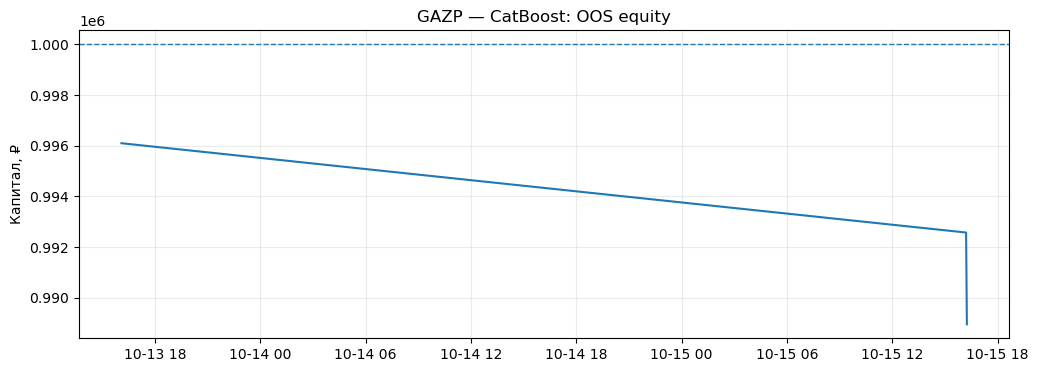

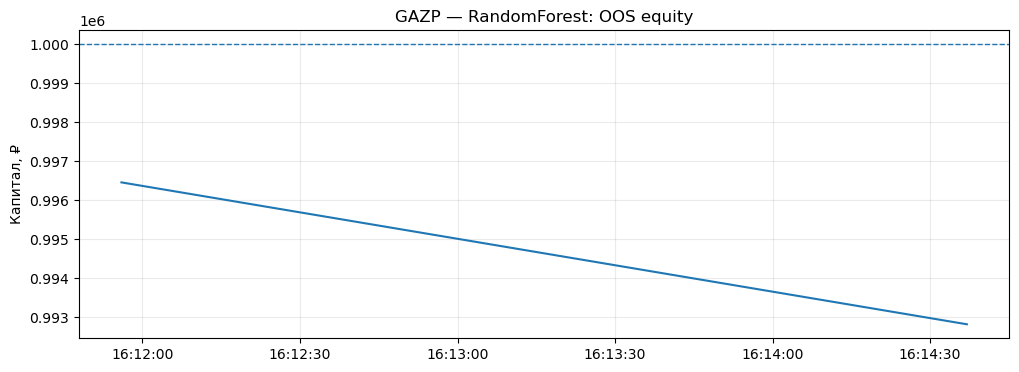

model,CatBoost,RandomForest
fold,,
WF1,-1.105206,-0.717438
WF2,0.000000,0.000000
WF3,0.000000,0.000000


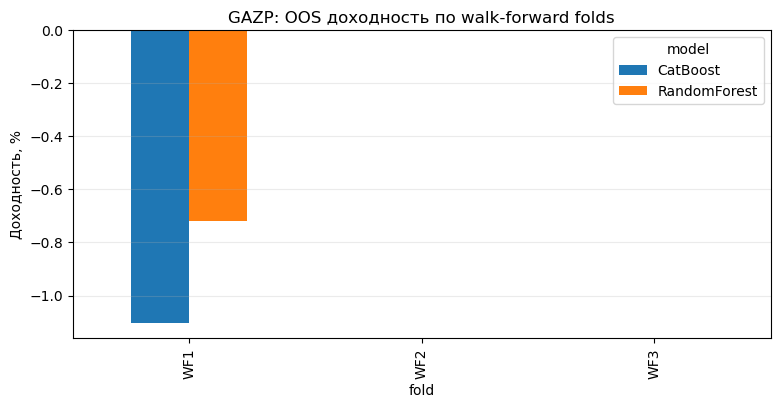

In [31]:
if not trade_results.empty:
    for model_name, d in trade_results.groupby("model"):
        d = d.sort_values("entry_ts").copy()
        d["equity"] = 1_000_000 * (1 + d["capital_return_pct"]/100).cumprod()
        fig, ax = plt.subplots(figsize=(12,4))
        ax.plot(d["entry_ts"], d["equity"], linewidth=1.5)
        ax.axhline(1_000_000, linestyle="--", linewidth=1)
        ax.set_title(f"{TICKER} — {model_name}: OOS equity")
        ax.set_ylabel("Капитал, ₽"); ax.grid(alpha=.25); plt.show()

if not fold_results.empty:
    pivot = fold_results.pivot(index="fold", columns="model", values="total_return_pct")
    display(pivot)
    ax = pivot.plot(kind="bar", figsize=(9,4), title=f"{TICKER}: OOS доходность по walk-forward folds")
    ax.set_ylabel("Доходность, %"); ax.grid(axis="y", alpha=.25); plt.show()

## 12. Финальная сборка модели для live-инференса (после OOS-проверки)

Этот шаг не участвует в оценке OOS. Он обучает deploy-артефакт на всех событиях, исходы которых уже полностью завершились к последнему доступному бару. Артефакт содержит GMM-режим и обе направленные модели CatBoost/RandomForest. Для live нужно передавать только актуальный вектор 474 признаков, сформированный тем же причинным pipeline.


In [44]:
import joblib

last_bar_ts = pd.Timestamp(ohlc.index.max())
resolved_idx = outcomes.index[pd.to_datetime(outcomes["t1"], utc=True) <= last_bar_ts]
X_final = X_all.loc[resolved_idx]
out_final = outcomes.loc[resolved_idx]
if len(X_final) < 200:
    print("Недостаточно полностью завершённых событий для deploy-артефакта:", len(X_final))
else:
    final_regime_state, _ = fit_regime_model(X_final, out_final)
    final_regimes = predict_regime(final_regime_state, X_final)
    deploy_models = {}
    deploy_medians = {}
    deploy_training_info = {}
    for model_name in ("CatBoost", "RandomForest"):
        deploy_models[model_name] = {}
        deploy_medians[model_name] = {}
        deploy_training_info[model_name] = {}
        for side in ("LONG", "SHORT"):
            model, info = fit_directional_model(model_name, side, X_final, final_regimes, out_final)
            deploy_models[model_name][side] = model
            deploy_training_info[model_name][side] = info
            regime_name = "BULLISH" if side == "LONG" else "BEARISH"
            idx_side = final_regimes.index[final_regimes["regime"] == regime_name]
            deploy_medians[model_name][side] = X_final.loc[idx_side].median().fillna(0.0)
    bundle = {
        "ticker": TICKER, "created_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
        "feature_columns": list(X_final.columns), "regime_state": final_regime_state,
        "models": deploy_models, "model_medians": deploy_medians,
        "training_info": deploy_training_info,
        "strategy_parameters": {"dollar_threshold": DOLLAR_THRESHOLD, "cusum_threshold": CUSUM_THRESHOLD,
            "pt_mult": PT_MULT, "sl_mult": SL_MULT, "vertical_horizon": VERTICAL_HORIZON,
            "vol_window": VOL_WINDOW, "round_trip_cost": ROUND_TRIP_COST,
            "risk_fraction": RISK_FRACTION, "max_leverage": MAX_LEVERAGE},
        "note": "Train-only causal GMM regime map + direction-specific models; no probability thresholding."
    }
    bundle_path = OUT_DIR / f"{TICKER}_AFML08_live_bundle.joblib"
    joblib.dump(bundle, bundle_path, compress=3)
    print("Live bundle saved:", bundle_path)
    display(pd.DataFrame([{
        "model":m, "side":s, **deploy_training_info[m][s]
    } for m in deploy_training_info for s in ("LONG","SHORT")]))


C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=10.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=10.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=10.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than a

Live bundle saved: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\outputs\afml08_adaptive_directional\SBER_AFML08_live_bundle.joblib


,model,side,status,n,class_counts
0,CatBoost,LONG,TOO_FEW_DIRECTIONAL_EVENTS,0,NaN
1,CatBoost,SHORT,OK,2210,"{0: 1473, 1: 737}"
2,RandomForest,LONG,TOO_FEW_DIRECTIONAL_EVENTS,0,NaN
3,RandomForest,SHORT,OK,2210,"{0: 1473, 1: 737}"


## 13. Сохранение результатов и артефактов

Сохраняем fold summary, сделки и train-only соответствия GMM-кластеров направлениям. Последние соответствия относятся к конкретному fold и не должны переноситься в live без переобучения соответствующего pipeline.

In [45]:
fold_path = OUT_DIR / f"{TICKER}_AFML08_fold_results.csv"
trade_path = OUT_DIR / f"{TICKER}_AFML08_oos_trades.csv"
regime_path = OUT_DIR / f"{TICKER}_AFML08_train_regime_maps.csv"
summary_path = OUT_DIR / f"{TICKER}_AFML08_combined_summary.csv"
fold_results.to_csv(fold_path,index=False,encoding="utf-8-sig")
trade_results.to_csv(trade_path,index=False,encoding="utf-8-sig")
regime_map_results.to_csv(regime_path,index=False,encoding="utf-8-sig")
combined_summary.to_csv(summary_path,index=False,encoding="utf-8-sig")
print("Сохранено:")
for p in (fold_path,trade_path,regime_path,summary_path): print(" -",p)

print("\\nAFML_08 завершён. Это объединённая ветка дальнейших directional regime экспериментов.")

Сохранено:
 - C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\outputs\afml08_adaptive_directional\SBER_AFML08_fold_results.csv
 - C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\outputs\afml08_adaptive_directional\SBER_AFML08_oos_trades.csv
 - C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\outputs\afml08_adaptive_directional\SBER_AFML08_train_regime_maps.csv
 - C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\outputs\afml08_adaptive_directional\SBER_AFML08_combined_summary.csv
\nAFML_08 завершён. Это объединённая ветка дальнейших directional regime экспериментов.


## 14. Как интерпретировать и что делать дальше

1. Сначала сравнить CatBoost и RandomForest по суммарной OOS доходности и просадке, затем отдельно LONG и SHORT.
2. Если модель торгует только одну сторону — это не ошибка: вторая сторона могла не получить достаточно направленных train-кластеров.
3. Если сделок мало, сначала проверить `train_regime_maps.csv`: возможно, GMM относит большинство событий в нейтральные кластеры или направленных событий недостаточно.
4. Если доходность положительна только в одном fold, считать результат нестабильным.
5. Не выбирать победителя по одному суммарному числу: важны согласованность fold, число сделок и просадка.
6. Следующий этап после первого запуска — не probability thresholding, а аудит режимов и сделок: какие GMM-кластеры стабильно дают преимущество, и воспроизводится ли оно на другом тикере.

**Контроль leakage:** scaler/PCA/GMM обучаются только на train X; GMM направление определяется только завершёнными train-сделками; направленные модели обучаются только на train; test используется один раз для OOS-результата; незавершённые train labels вычищаются purging; entry — следующий OPEN; в рамках инструмента сделки не перекрываются.

**Не включено намеренно:** Optuna и дополнительные варианты кластеризаторов. Сначала нужно получить базовый воспроизводимый результат этой адаптивной архитектуры. HDBSCAN можно добавить позже как отдельное сравнение режима, если GMM окажется слабым или нестабильным.